# Factors Associated with Cognitive Processing Speed Among U.S. Adults Aged 60 and Older

**NHANES 2011–2014 | Survey-weighted cross-sectional analysis**

## Research question
How are age, sex, education, history of stroke, and depressive symptoms associated with Digit Symbol Substitution Test (DSST) performance among U.S. adults aged 60 and older?

The analysis uses NHANES 2011–2012 and 2013–2014 data. The outcome is the NHANES cognitive-functioning score `CFDDS`. This is an observational, cross-sectional analysis: associations are not interpreted as causal effects or as evidence of longitudinal cognitive decline.

## Reproducibility
Place the eight NHANES `.xpt` files listed in the README in the same directory as this notebook. The analysis uses Python and the `svy` package for survey-weighted regression. The R `survey` package is used only for an optional cross-check.

## 1. Imports and load NHANES data

Load the cognitive-functioning, demographic, medical-condition, and depression-questionnaire files for both cycles. File names are case-sensitive on some systems, so the code uses the lowercase `.xpt` extension.

In [10]:
from pathlib import Path
import shutil
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import svy
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

DATA_DIR = Path.cwd()

cfq_2011 = pd.read_sas(DATA_DIR / "CFQ_G.xpt")
cfq_2013 = pd.read_sas(DATA_DIR / "CFQ_H.xpt")
demo_2011 = pd.read_sas(DATA_DIR / "DEMO_G.xpt")
demo_2013 = pd.read_sas(DATA_DIR / "DEMO_H.xpt")
mcq_2011 = pd.read_sas(DATA_DIR / "MCQ_G.xpt")
mcq_2013 = pd.read_sas(DATA_DIR / "MCQ_H.xpt")
dpq_2011 = pd.read_sas(DATA_DIR / "DPQ_G.xpt")
dpq_2013 = pd.read_sas(DATA_DIR / "DPQ_H.xpt")

print("Cognitive files:", cfq_2011.shape, cfq_2013.shape)
print("Demographic files:", demo_2011.shape, demo_2013.shape)
print("Medical-condition files:", mcq_2011.shape, mcq_2013.shape)
print("Depression-questionnaire files:", dpq_2011.shape, dpq_2013.shape)

Cognitive files: (1687, 19) (1785, 19)
Demographic files: (9756, 48) (10175, 47)
Medical-condition files: (9364, 92) (9770, 95)
Depression-questionnaire files: (5615, 11) (5924, 11)


## 2. Combine cycles and prepare the analysis dataset

The cycle label is retained during merging so records from different survey cycles are not accidentally matched. Participants without a valid DSST score are excluded. Education response codes 7 and 9 are treated as missing; sex and education are given readable labels.

In [11]:
for frame, cycle in [
    (cfq_2011, "2011-2012"),
    (cfq_2013, "2013-2014"),
    (demo_2011, "2011-2012"),
    (demo_2013, "2013-2014"),
]:
    frame["cycle"] = cycle

cfq = pd.concat([cfq_2011, cfq_2013], ignore_index=True)
demo = pd.concat([demo_2011, demo_2013], ignore_index=True)

demo_selected = demo[
    ["SEQN", "RIDAGEYR", "RIAGENDR", "DMDEDUC2",
     "WTMEC2YR", "SDMVPSU", "SDMVSTRA", "cycle"]
].copy()

df = cfq.merge(
    demo_selected,
    on=["SEQN", "cycle"],
    how="left",
    validate="one_to_one"
)

analysis = df.dropna(subset=["CFDDS"]).copy()
analysis["DMDEDUC2"] = analysis["DMDEDUC2"].replace({7: np.nan, 9: np.nan})

analysis["sex"] = analysis["RIAGENDR"].map({1: "Male", 2: "Female"})
education_labels = {
    1: "Less than 9th grade",
    2: "9th–11th grade",
    3: "High school graduate/GED",
    4: "Some college/AA degree",
    5: "College graduate or above",
}
analysis["education"] = analysis["DMDEDUC2"].map(education_labels)

print("Combined cognitive records:", len(cfq))
print("Participants with valid CFDDS:", len(analysis))
print("Unique participant IDs:", analysis["SEQN"].nunique())
print("Age range:", analysis["RIDAGEYR"].min(), "to", analysis["RIDAGEYR"].max())
display(analysis[["CFDDS", "RIDAGEYR"]].describe().round(2))

Combined cognitive records: 3472
Participants with valid CFDDS: 3014
Unique participant IDs: 3014
Age range: 60.0 to 80.0


,CFDDS,RIDAGEYR
count,3014.00,3014.00
mean,45.46,69.49
std,17.44,6.78
min,0.00,60.00
25%,33.00,63.00
50%,45.00,69.00
75%,58.00,75.00
max,105.00,80.00


## 3. Add stroke history and PHQ-9 score

Stroke history is based on NHANES variable `MCQ160F` (yes = 1, no = 2). PHQ-9 is calculated only when all nine items are available. NHANES special missing codes 7 and 9 are excluded; a near-zero SAS representation is converted to zero before scoring.

In [12]:
mcq = pd.concat([mcq_2011, mcq_2013], ignore_index=True)
mcq_stroke = mcq[["SEQN", "MCQ160F"]].copy()
mcq_stroke["stroke_history"] = mcq_stroke["MCQ160F"].map({1.0: "Yes", 2.0: "No"})
mcq_stroke = mcq_stroke[["SEQN", "stroke_history"]]

analysis = analysis.merge(
    mcq_stroke, on="SEQN", how="left", validate="one_to_one"
)

dpq = pd.concat([dpq_2011, dpq_2013], ignore_index=True)
phq9_cols = [f"DPQ{i:03d}" for i in range(10, 100, 10)]

for col in phq9_cols:
    dpq[col] = dpq[col].mask(dpq[col] < 1e-10, 0)
    dpq[col] = dpq[col].replace([7, 9], np.nan)

dpq["PHQ9_score"] = dpq[phq9_cols].sum(axis=1, min_count=9)
dpq_scores = dpq[["SEQN", "PHQ9_score"]].copy()

analysis = analysis.merge(
    dpq_scores, on="SEQN", how="left", validate="one_to_one"
)

print("Stroke history:")
display(analysis["stroke_history"].value_counts(dropna=False).rename("participants"))
print("PHQ-9 complete scores:", int(analysis["PHQ9_score"].notna().sum()))

Stroke history:


stroke_history
No     2797
Yes     212
NaN       5
Name: participants, dtype: int64

PHQ-9 complete scores: 2944


## 4. Define the survey design and final model sample

For the combined four-year period, the two-year MEC examination weight is divided by two. The primary model uses complete cases for the outcome, predictors, weight, strata, and PSU variables. Complete-case analysis can introduce selection bias if missingness is systematic.

In [13]:
analysis["WTMEC4YR"] = analysis["WTMEC2YR"] / 2

model_variables = [
    "CFDDS", "RIDAGEYR", "sex", "education", "stroke_history",
    "PHQ9_score", "WTMEC4YR", "SDMVSTRA", "SDMVPSU"
]
model_data_phq9 = analysis.dropna(subset=model_variables).copy()

print("Records with a DSST score:", len(analysis))
print("Final complete-case model sample:", len(model_data_phq9))
print("Excluded from model sample:", len(analysis) - len(model_data_phq9))

model_pl_phq9 = pl.from_pandas(model_data_phq9)
design_phq9 = svy.Design(
    stratum="SDMVSTRA",
    psu="SDMVPSU",
    wgt="WTMEC4YR",
    wr=True
)
sample_phq9 = svy.Sample(data=model_pl_phq9, design=design_phq9)

Records with a DSST score: 3014
Final complete-case model sample: 2936
Excluded from model sample: 78


## 5. Descriptive exploration

The tables and plots below are **unweighted descriptive summaries**. They are useful for exploring patterns in this sample, but they are not survey-weighted population estimates.

,count,mean,std
stroke_history,,,
No,2730,46.40,17.21
Yes,206,36.28,16.76


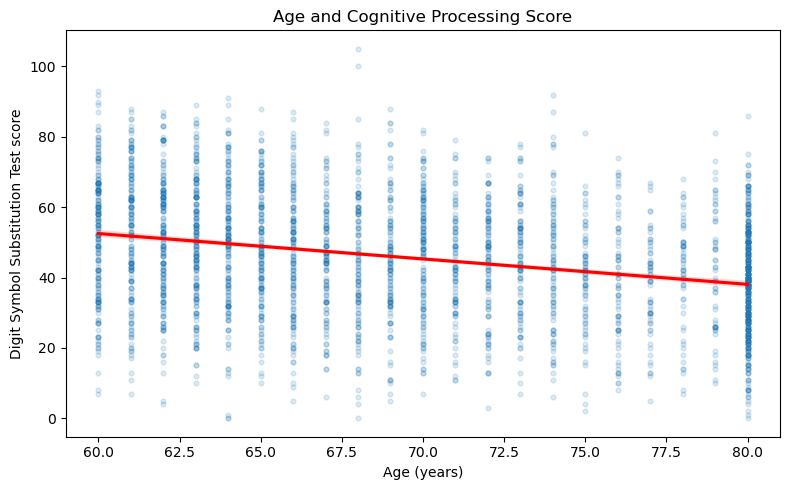

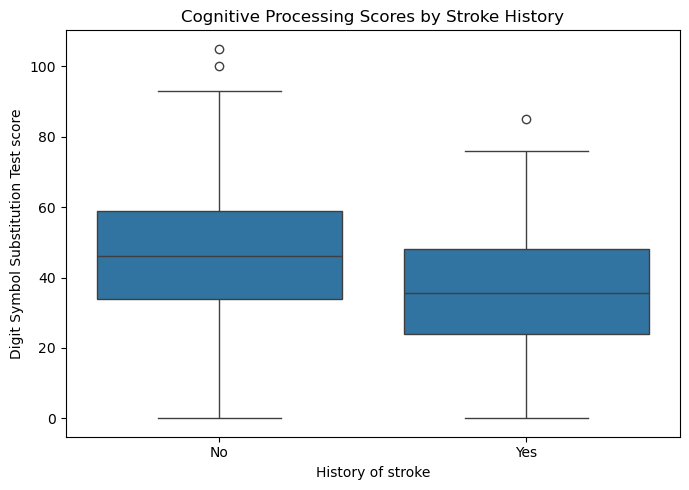

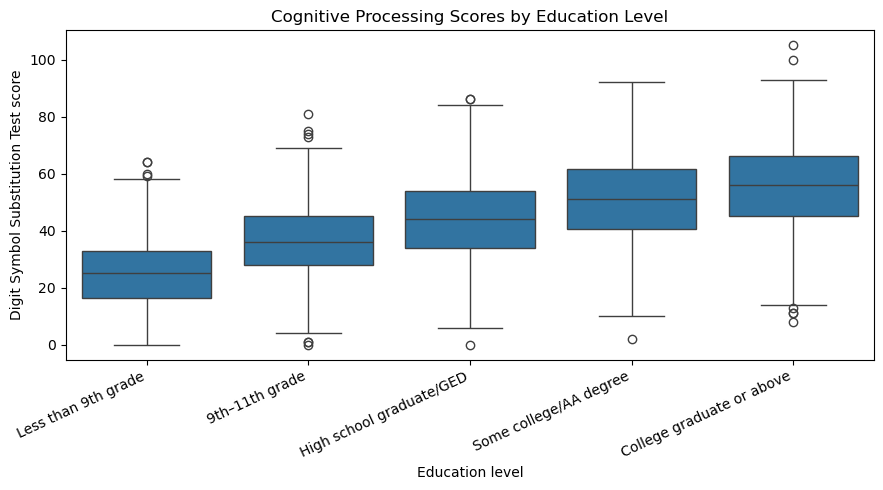

In [14]:
descriptive_by_stroke = (
    model_data_phq9.groupby("stroke_history")["CFDDS"]
    .agg(["count", "mean", "std"])
    .round(2)
)
display(descriptive_by_stroke)

age_summary = (
    model_data_phq9.groupby("RIDAGEYR", observed=True)["CFDDS"]
    .agg(["count", "mean"])
    .reset_index()
)

plt.figure(figsize=(8, 5))
sns.regplot(
    data=model_data_phq9, x="RIDAGEYR", y="CFDDS",
    scatter_kws={"alpha": 0.15, "s": 12},
    line_kws={"color": "red"}
)
plt.xlabel("Age (years)")
plt.ylabel("Digit Symbol Substitution Test score")
plt.title("Age and Cognitive Processing Score")
plt.tight_layout()
plt.savefig("age_cognitive_score.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 5))
sns.boxplot(data=model_data_phq9, x="stroke_history", y="CFDDS")
plt.xlabel("History of stroke")
plt.ylabel("Digit Symbol Substitution Test score")
plt.title("Cognitive Processing Scores by Stroke History")
plt.tight_layout()
plt.savefig("stroke_history_score.png", dpi=300, bbox_inches="tight")
plt.show()

education_order = [
    "Less than 9th grade",
    "9th–11th grade",
    "High school graduate/GED",
    "Some college/AA degree",
    "College graduate or above",
]
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=model_data_phq9, x="education", y="CFDDS",
    order=education_order
)
plt.xlabel("Education level")
plt.ylabel("Digit Symbol Substitution Test score")
plt.title("Cognitive Processing Scores by Education Level")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("education_level_score.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Primary survey-weighted regression

The primary model estimates associations between DSST score and age, sex, education, stroke history, and PHQ-9 score. Reference categories are female, 9th–11th grade, and no history of stroke. Coefficients describe adjusted associations, not causal effects.

In [15]:
model_phq9 = sample_phq9.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        svy.Cat("sex", ref="Female"),
        svy.Cat("education", ref="9th–11th grade"),
        svy.Cat("stroke_history", ref="No"),
        "PHQ9_score",
    ],
    family="gaussian",
)
print(model_phq9)

primary_rows = []
for coef in model_phq9._ensure_fitted().coefs:
    primary_rows.append({
        "Variable": coef.term,
        "Coefficient": coef.est,
        "95% CI lower": coef.lci,
        "95% CI upper": coef.uci,
        "p-value": coef.wald.p_value,
    })
results_df = pd.DataFrame(primary_rows)
display(results_df.round(3))

╭──────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                           │
│                                                                                                           │
│ Observations         2936  AIC           23422.7423                                                       │
│ DF Residuals           24  BIC                    -                                                       │
│ Deviance      496734.4383  Scale           169.7077                                                       │
│ R-squared         0.40579  R-sq (adj)       0.40417                                                       │
│                            Iterations             2                                                       │
│ F-stat (adj)     92.52234  Prob (F-adj)      <0.001                                                       │
│                                                                                                           │
│                                                                                                           │
│  Term                                      Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                           109.35799    3.46223    31.58602   <0.001   102.21230   116.50367  │
│  RIDAGEYR                               -0.90368    0.04497   -20.09420   <0.001    -0.99650    -0.81086  │
│  sex_Male                               -5.29250    0.47143   -11.22637   <0.001    -6.26549    -4.31951  │
│  education_College graduate or above    16.46195    1.10563    14.88916   <0.001    14.18004    18.74387  │
│  education_High school graduate/GED      6.64003    0.78328     8.47722   <0.001     5.02342     8.25664  │
│  education_Less than 9th grade         -11.34838    1.36001    -8.34430   <0.001   -14.15531    -8.54145  │
│  education_Some college/AA degree       12.06547    0.87838    13.73608   <0.001    10.25259    13.87835  │
│  stroke_history_Yes                     -5.41908    1.08876    -4.97730   <0.001    -7.66617    -3.17199  │
│  PHQ9_score                             -0.61123    0.09480    -6.44765   <0.001    -0.80688    -0.41557  │
│                                                                                                           │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────╯

,Variable,Coefficient,95% CI lower,95% CI upper,p-value
0,_intercept_,109.358,102.212,116.504,0.0
1,RIDAGEYR,-0.904,-0.996,-0.811,0.0
2,sex_Male,-5.293,-6.265,-4.320,0.0
3,education_College graduate or above,16.462,14.180,18.744,0.0
4,education_High school graduate/GED,6.640,5.023,8.257,0.0
5,education_Less than 9th grade,-11.348,-14.155,-8.541,0.0
6,education_Some college/AA degree,12.065,10.253,13.878,0.0
7,stroke_history_Yes,-5.419,-7.666,-3.172,0.0
8,PHQ9_score,-0.611,-0.807,-0.416,0.0


## 7. Supplementary age-by-education interaction model

This model tests whether the association between age and DSST score differs across education categories. The joint Wald test evaluates the interaction terms together. The primary model remains the main model because it is simpler to interpret.

In [16]:
model_interaction_phq9 = sample_phq9.glm.fit(
    y="CFDDS",
    x=[
        "RIDAGEYR",
        svy.Cat("sex", ref="Female"),
        svy.Cat("education", ref="9th–11th grade"),
        svy.Cat("stroke_history", ref="No"),
        "PHQ9_score",
        svy.Cross("RIDAGEYR", svy.Cat("education", ref="9th–11th grade")),
    ],
    family="gaussian",
)
print(model_interaction_phq9)

fit_interaction = model_interaction_phq9._ensure_fitted()
interaction_indices = [
    i for i, coef in enumerate(fit_interaction.coefs)
    if coef.term.startswith("RIDAGEYR:education_")
]
beta = np.array([fit_interaction.coefs[i].est for i in interaction_indices])
cov = np.asarray(fit_interaction.cov_matrix)[
    np.ix_(interaction_indices, interaction_indices)
]

q = len(interaction_indices)
wald_chi2 = beta @ np.linalg.solve(cov, beta)
f_stat = wald_chi2 / q
df_den = fit_interaction._design_df()
p_value = stats.f.sf(f_stat, q, df_den)

print(f"Joint interaction test: F({q}, {int(df_den)}) = {f_stat:.3f}, p = {p_value:.4f}")

interaction_rows = []
for coef in fit_interaction.coefs:
    interaction_rows.append({
        "Variable": coef.term,
        "Coefficient": coef.est,
        "95% CI lower": coef.lci,
        "95% CI upper": coef.uci,
        "p-value": coef.wald.p_value,
    })
results_interaction_df = pd.DataFrame(interaction_rows)
display(results_interaction_df.round(3))

╭───────────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                                    │
│                                                                                                                    │
│ Observations         2936  AIC           23407.6668                                                                │
│ DF Residuals           20  BIC                    -                                                                │
│ Deviance      492358.4430  Scale           168.4428                                                                │
│ R-squared         0.41103  R-sq (adj)       0.40861                                                                │
│                            Iterations             2                                                                │
│ F-stat (adj)     70.03115  Prob (F-adj)      <0.001                                                                │
│                                                                                                                    │
│                                                                                                                    │
│  Term                                               Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                                     94.14620   10.19501     9.23454   <0.001    72.87978   115.41261  │
│  RIDAGEYR                                        -0.68855    0.14127    -4.87400   <0.001    -0.98324    -0.39387  │
│  sex_Male                                        -5.20189    0.46049   -11.29635   <0.001    -6.16247    -4.24132  │
│  education_College graduate or above             40.65355   11.82040     3.43927   0.0026    15.99663    65.31046  │
│  education_High school graduate/GED               9.19633   11.72178     0.78455   0.4419   -15.25487    33.64752  │
│  education_Less than 9th grade                  -24.33316   15.15250    -1.60588   0.1240   -55.94072     7.27439  │
│  education_Some college/AA degree                37.73039   11.18459     3.37343   0.0030    14.39975    61.06103  │
│  stroke_history_Yes                              -5.39927    1.05262    -5.12936   <0.001    -7.59499    -3.20354  │
│  PHQ9_score                                      -0.59536    0.09181    -6.48504   <0.001    -0.78686    -0.40386  │
│  RIDAGEYR:education_College graduate or above    -0.34757    0.16272    -2.13599   0.0452    -0.68701    -0.00814  │
│  RIDAGEYR:education_High school graduate/GED     -0.03474    0.16601    -0.20927   0.8364    -0.38103     0.31155  │
│  RIDAGEYR:education_Less than 9th grade           0.18086    0.20866     0.86678   0.3963    -0.25440     0.61613  │
│  RIDAGEYR:education_Some college/AA degree       -0.36798    0.15796    -2.32964   0.0304    -0.69747    -0.03849  │
│                                                                                                                    │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯


Joint interaction test: F(4, 20) = 5.319, p = 0.0044


,Variable,Coefficient,95% CI lower,95% CI upper,p-value
0,_intercept_,94.146,72.880,115.413,0.000
1,RIDAGEYR,-0.689,-0.983,-0.394,0.000
2,sex_Male,-5.202,-6.162,-4.241,0.000
3,education_College graduate or above,40.654,15.997,65.310,0.003
4,education_High school graduate/GED,9.196,-15.255,33.648,0.442
5,education_Less than 9th grade,-24.333,-55.941,7.274,0.124
6,education_Some college/AA degree,37.730,14.400,61.061,0.003
7,stroke_history_Yes,-5.399,-7.595,-3.204,0.000
8,PHQ9_score,-0.595,-0.787,-0.404,0.000
9,RIDAGEYR:education_College graduate or above,-0.348,-0.687,-0.008,0.045


## 8. Model checks (OLS approximation)

Residual plots, Cook's distance, and VIF are calculated from an ordinary least-squares model with the same predictors. These are supplementary diagnostics; they do not fully validate residual behavior under the complex survey-weighted model.

OLS observations: 2936
OLS R-squared: 0.407


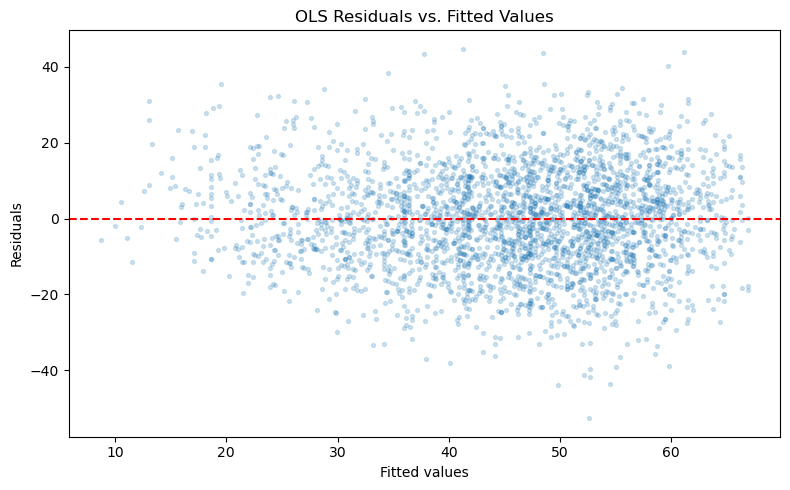

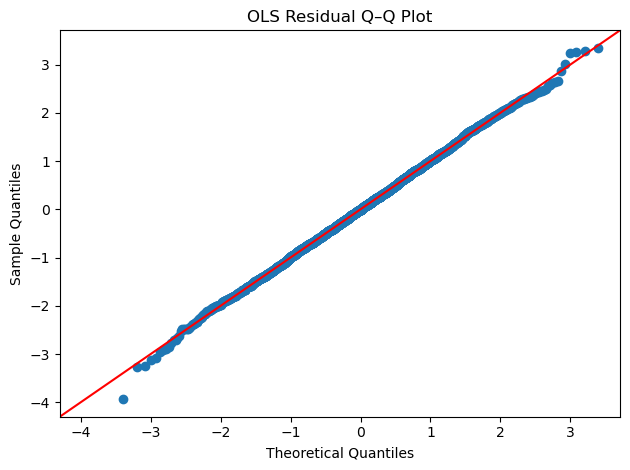

Observations with Cook's distance > 4/n: 143
Maximum Cook's distance: 0.0065


,Variable,VIF
0,Intercept,117.93
1,C(sex)[T.Male],1.03
2,C(education)[T.College graduate or above],2.07
3,C(education)[T.High school graduate/GED],2.05
4,C(education)[T.Less than 9th grade],1.60
5,C(education)[T.Some college/AA degree],2.18
6,C(stroke_history)[T.Yes],1.03
7,RIDAGEYR,1.02
8,PHQ9_score,1.06


In [17]:
ols_phq9 = smf.ols(
    "CFDDS ~ RIDAGEYR + C(sex) + C(education) + C(stroke_history) + PHQ9_score",
    data=model_data_phq9
).fit()

print("OLS observations:", int(ols_phq9.nobs))
print("OLS R-squared:", round(ols_phq9.rsquared, 3))

plt.figure(figsize=(8, 5))
plt.scatter(ols_phq9.fittedvalues, ols_phq9.resid, alpha=0.2, s=8)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("OLS Residuals vs. Fitted Values")
plt.tight_layout()
plt.savefig("residuals_vs_fitted_values.png", dpi=300, bbox_inches="tight")
plt.show()

sm.qqplot(ols_phq9.resid, line="45", fit=True)
plt.title("OLS Residual Q–Q Plot")
plt.tight_layout()
plt.savefig("q_q_plot.png", dpi=300, bbox_inches="tight")
plt.show()

influence = ols_phq9.get_influence()
cooks_d = influence.cooks_distance[0]
print("Observations with Cook's distance > 4/n:", int((cooks_d > 4 / len(model_data_phq9)).sum()))
print("Maximum Cook's distance:", round(float(cooks_d.max()), 4))

X = ols_phq9.model.exog
names = ols_phq9.model.exog_names
vif = pd.DataFrame({
    "Variable": names,
    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]
})
display(vif.round(2))

## 9. Optional cross-check with R

This cell exports the final model sample and, if R is installed and available on the system path, fits the corresponding model with the R `survey` package. It is optional and can be skipped if R or the package is not installed.

In [18]:
csv_path = DATA_DIR / "nhanes_model_phq9.csv"
model_data_phq9.to_csv(csv_path, index=False)
print(f"Exported model sample to: {csv_path}")

r_executable = shutil.which("R")
if r_executable is None:
    print("R was not found on PATH; skipping the optional R cross-check.")
else:
    r_code = r'''
    library(survey)
    df <- read.csv("nhanes_model_phq9.csv")
    df$sex <- relevel(factor(df$sex), ref = "Female")
    df$education <- relevel(factor(df$education), ref = "9th–11th grade")
    df$stroke_history <- relevel(factor(df$stroke_history), ref = "No")
    nhanes_design <- svydesign(
      ids = ~SDMVPSU, strata = ~SDMVSTRA, weights = ~WTMEC4YR,
      data = df, nest = TRUE
    )
    fit <- svyglm(
      CFDDS ~ RIDAGEYR + sex + education + stroke_history + PHQ9_score,
      design = nhanes_design
    )
    print(summary(fit))
    print(confint(fit))
    '''
    result = subprocess.run(
        [r_executable, "--vanilla", "-e", r_code],
        cwd=str(DATA_DIR), capture_output=True, text=True
    )
    print(result.stdout)
    if result.stderr:
        print("R messages:")
        print(result.stderr)
    print("R return code:", result.returncode)

Exported model sample to: /Users/Marcin_1/Desktop/Demographics/nhanes_model_phq9.csv

R version 4.6.1 (2026-06-24) -- "Happy Hop"
Copyright (C) 2026 The R Foundation for Statistical Computing
Platform: aarch64-apple-darwin23

R is free software and comes with ABSOLUTELY NO WARRANTY.
You are welcome to redistribute it under certain conditions.
Type 'license()' or 'licence()' for distribution details.

  Natural language support but running in an English locale

R is a collaborative project with many contributors.
Type 'contributors()' for more information and
'citation()' on how to cite R or R packages in publications.

Type 'demo()' for some demos, 'help()' for on-line help, or
'help.start()' for an HTML browser interface to help.
Type 'q()' to quit R.

> 
>     library(survey)
>     df <- read.csv("nhanes_model_phq9.csv")
>     df$sex <- relevel(factor(df$sex), ref = "Female")
>     df$education <- relevel(factor(df$education), ref = "9th–11th grade")
>     df$stroke_history <- releve

## 10. Interpretation and limitations

The survey-weighted models estimate adjusted associations with DSST performance in U.S. adults aged 60 and older during NHANES 2011–2014. Interpret coefficient estimates alongside their confidence intervals and p-values.

Key limitations:
- Cross-sectional data cannot establish causality or measure within-person cognitive decline.
- DSST is a specific cognitive performance measure and is not a diagnosis of dementia.
- Complete-case exclusion may create selection bias.
- Residual confounding and model specification remain possible.
- Descriptive plots are unweighted, whereas regression models account for the survey design.
- Results reflect the older U.S. population and survey period studied; they may not generalize to other populations or periods.

For publication, run the notebook from top to bottom with the required source files and review the resulting outputs before committing it to GitHub.